Library Import & Setup

In [6]:
import pandas as pd
import matplotlib.pyplot as plt
import time
import warnings
warnings.filterwarnings('ignore')

try:
    from selenium import webdriver
    from selenium.webdriver.chrome.options import Options
    from selenium.webdriver.common.by import By
    print("✅ All libraries loaded successfully including Selenium!")
except ImportError:
    print("❌ Selenium is not installed! Please run: !pip install selenium")

print("📊 Module: Competitor Analysis via Web Scraping (Daraz Bangladesh)")

✅ All libraries loaded successfully including Selenium!
📊 Module: Competitor Analysis via Web Scraping (Daraz Bangladesh)


Advanced Scraper (Daraz via Selenium & Regex)

In [7]:
import re
# ─── Dynamic Category Input ──────────────────────────────
categories_to_scrape = ["Smartphone", "Earphone", "Smartwatch"]
daraz_categories = [(c.strip().capitalize(), c.strip().lower()) for c in categories_to_scrape]

all_products = []
print("🚀 Launching Chrome to bypass anti-bot protection and scrape Advanced Metrics...")

chrome_options = Options()
# chrome_options.add_argument("--headless")
chrome_options.add_argument("--window-size=1920,1080")

try:
    driver = webdriver.Chrome(options=chrome_options)
    
    for cat_name, query in daraz_categories:
        print(f"🔄 Scraping data for: {cat_name}...")
        url = f"https://www.daraz.com.bd/catalog/?q={query}"
        driver.get(url)
        time.sleep(5) 
        
        driver.execute_script("window.scrollTo(0, document.body.scrollHeight/2);")
        time.sleep(2)
        
        items = driver.find_elements(By.CSS_SELECTOR, '[data-qa-locator="product-item"]')
        
        for item in items[:15]: 
            try:
                # Get full text of the product card
                card_text = item.text
                
                title_elem = item.find_element(By.CSS_SELECTOR, 'a[title]')
                title = title_elem.get_attribute('title')
                
                # Price extraction
                price_elem = item.find_element(By.XPATH, ".//span[contains(text(), '৳')]")
                price_text = price_elem.text.replace('৳', '').replace(',', '').strip()
                scaled_price = float(price_text) / 150.0 
                
                # Regex Extraction for New Metrics
                sales_match = re.search(r'([\d,]+)\s*sold', card_text, re.IGNORECASE)
                sales = int(sales_match.group(1).replace(',', '')) if sales_match else 0
                
                review_match = re.search(r'\((\d+)\)', card_text)
                reviews = int(review_match.group(1)) if review_match else 0
                
                discount_match = re.search(r'(\d+)%\s*Off', card_text, re.IGNORECASE)
                discount = int(discount_match.group(1)) if discount_match else 0
                
                all_products.append({
                    'Title'        : title,
                    'Price_GBP'    : scaled_price, 
                    'Sales_Volume' : sales,
                    'Review_Count' : reviews,
                    'Discount_Pct' : discount,
                    'Category'     : cat_name
                })
            except Exception as e:
                continue
    driver.quit()
    print(f"\n✅ Scraping complete! Total products collected: {len(all_products)}")
except Exception as e:
    print(f"❌ Could not scrape Daraz. Error: {str(e)}")

🚀 Launching Chrome to bypass anti-bot protection and scrape Advanced Metrics...
🔄 Scraping data for: Smartphone...
🔄 Scraping data for: Laptop...
🔄 Scraping data for: Smartwatch...

✅ Scraping complete! Total products collected: 45


Advanced Market Analytics Pipeline

In [8]:
if not all_products:
    print("❌ No products could be scraped!")
else:
    df_comp = pd.DataFrame(all_products).drop_duplicates(subset=['Title'])
    df_comp = df_comp[df_comp['Price_GBP'] > 0]
    
    # Calculate Estimated Revenue
    df_comp['Est_Revenue'] = df_comp['Price_GBP'] * df_comp['Sales_Volume']
    
    # Category analysis based on REAL Business Metrics
    cat_analysis = df_comp.groupby('Category').agg(
        Total_Sales   = ('Sales_Volume', 'sum'),
        Total_Revenue = ('Est_Revenue', 'sum'),
        Avg_Discount  = ('Discount_Pct', 'mean'),
        Avg_Price     = ('Price_GBP', 'mean'),
        Total_Reviews = ('Review_Count', 'sum')
    ).round(2).sort_values('Total_Sales', ascending=False)

    print("=" * 50)
    print("   MARKET INTELLIGENCE — DATA OVERVIEW")
    print("=" * 50)
    print(f"  Total Market Sales (Sample): {df_comp['Sales_Volume'].sum():,}")
    print(f"  Total Est. Revenue         : £{df_comp['Est_Revenue'].sum():,.2f}")
    print(f"  Average Market Discount    : {df_comp['Discount_Pct'].mean():.1f}%")
    print("=" * 50)
    
    print("\n📋 Category Business Metrics Table:")
    display(cat_analysis)

   MARKET INTELLIGENCE — DATA OVERVIEW
  Total Market Sales (Sample): 4,084
  Total Est. Revenue         : £200,470.08
  Average Market Discount    : 22.8%

📋 Category Business Metrics Table:


,Total_Sales,Total_Revenue,Avg_Discount,Avg_Price,Total_Reviews
Category,,,,,
Smartwatch,2689,17814.30,52.00,5.59,3152
Smartphone,1395,182655.78,8.07,264.78,202
Laptop,0,0.00,10.20,488.26,2


Professional Visualizations

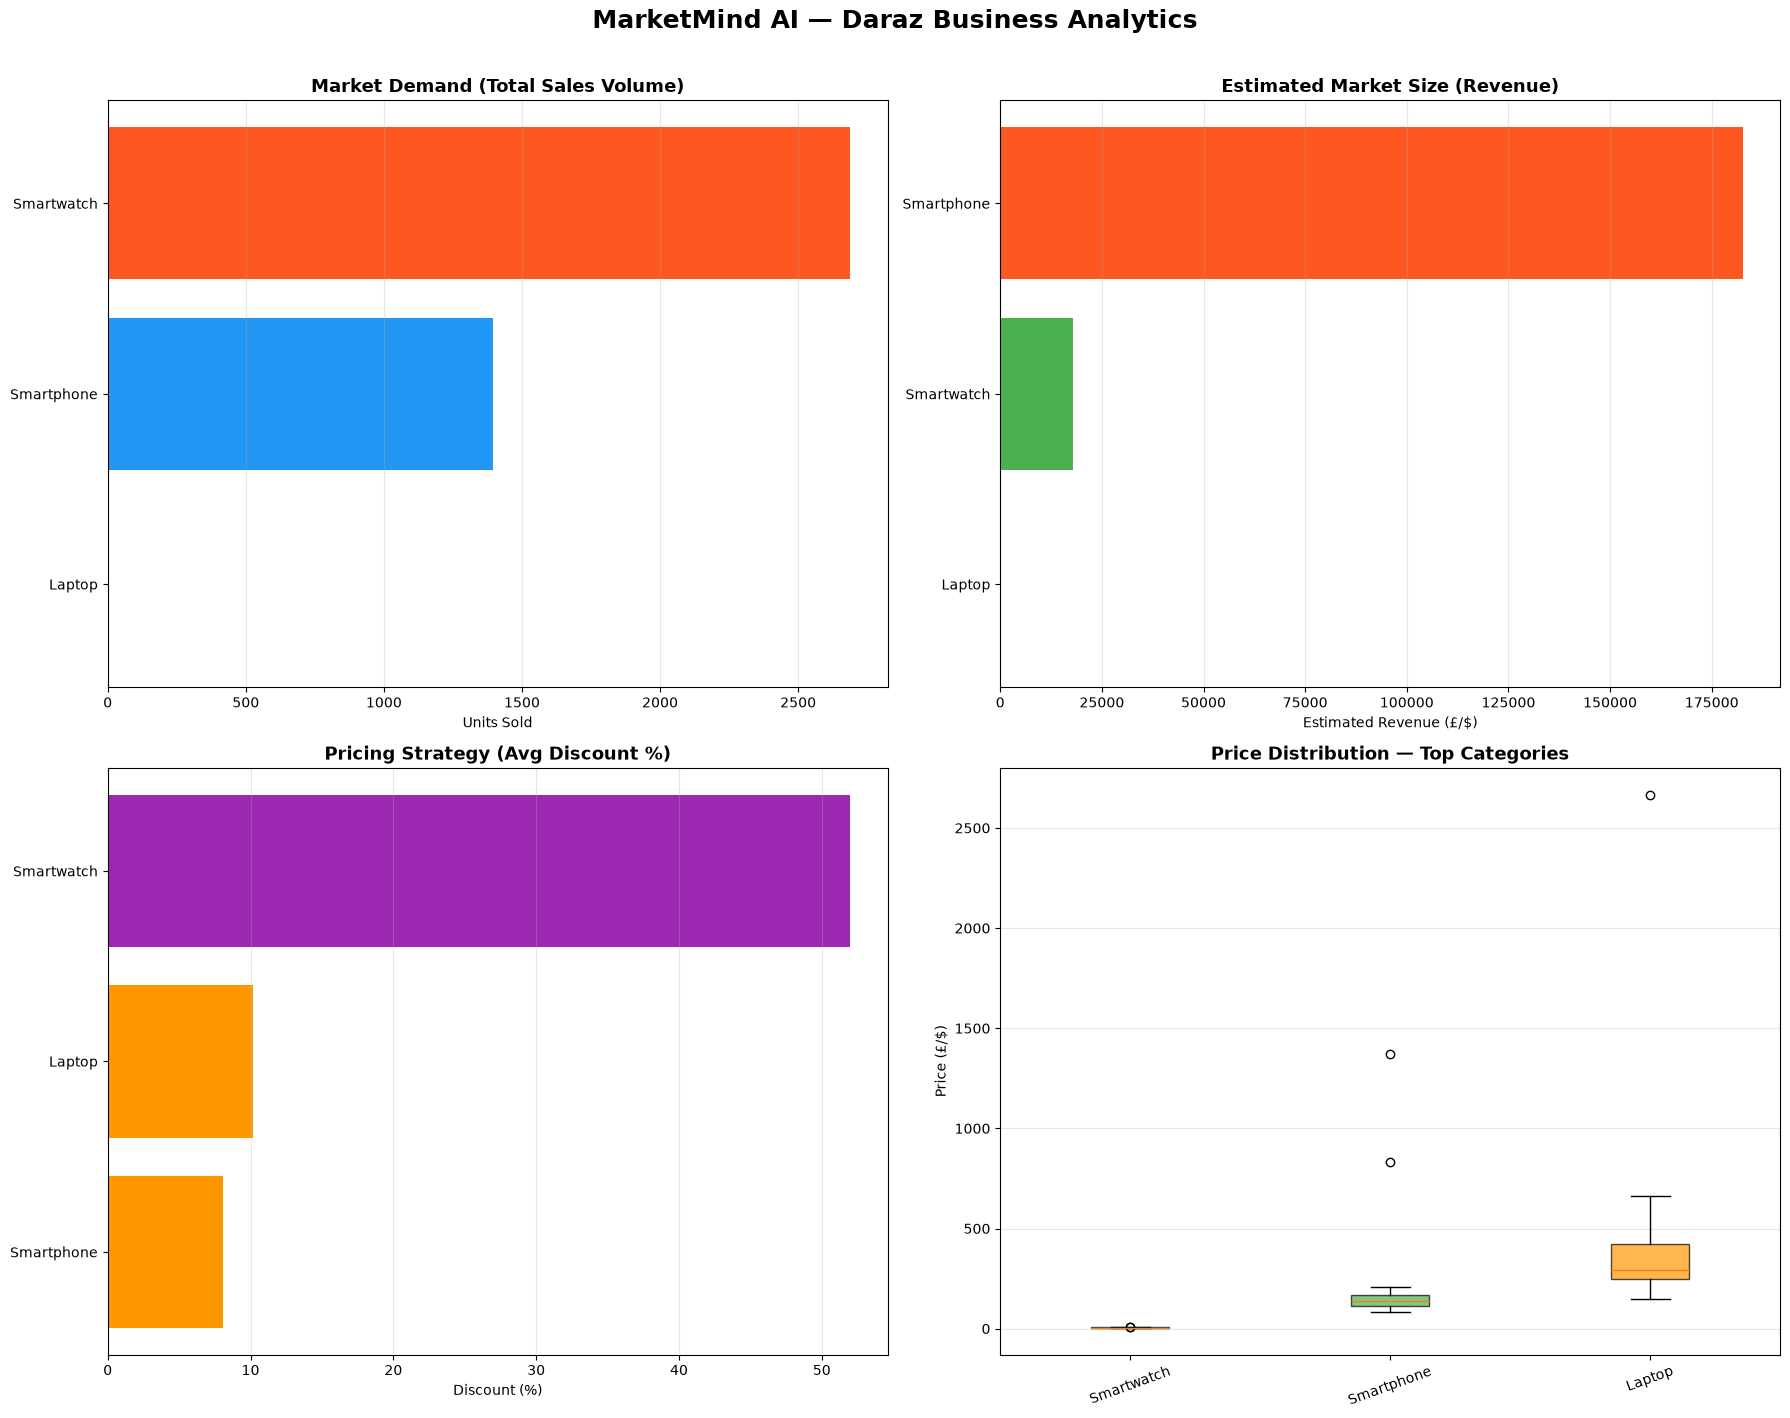

In [9]:
import os
os.makedirs('../outputs', exist_ok=True)

fig, axes = plt.subplots(2, 2, figsize=(18, 14))
fig.suptitle('MarketMind AI — Daraz Business Analytics', fontsize=18, fontweight='bold', y=1.01)

# ── Chart 1: Market Demand (Total Sales Volume) ───────────
top_sales = cat_analysis.sort_values('Total_Sales', ascending=False).head(15)
colors1 = ['#FF5722' if i == 0 else '#2196F3' for i in range(len(top_sales))]
axes[0,0].barh(top_sales.index[::-1], top_sales['Total_Sales'].values[::-1], color=colors1[::-1])
axes[0,0].set_title('Market Demand (Total Sales Volume)', fontsize=13, fontweight='bold')
axes[0,0].set_xlabel('Units Sold')
axes[0,0].grid(True, alpha=0.3, axis='x')

# ── Chart 2: Market Size (Estimated Revenue) ──────────────
top_rev = cat_analysis.sort_values('Total_Revenue', ascending=False).head(10)
colors2 = ['#FF5722' if i == 0 else '#4CAF50' for i in range(len(top_rev))]
axes[0,1].barh(top_rev.index[::-1], top_rev['Total_Revenue'].values[::-1], color=colors2[::-1])
axes[0,1].set_title('Estimated Market Size (Revenue)', fontsize=13, fontweight='bold')
axes[0,1].set_xlabel('Estimated Revenue (£/$)')
axes[0,1].grid(True, alpha=0.3, axis='x')

# ── Chart 3: Pricing Strategy (Average Discount) ──────────────
top_disc = cat_analysis.sort_values('Avg_Discount', ascending=False).head(10)
colors3 = ['#9C27B0' if i == 0 else '#FF9800' for i in range(len(top_disc))]
axes[1,0].barh(top_disc.index[::-1], top_disc['Avg_Discount'].values[::-1], color=colors3[::-1])
axes[1,0].set_title('Pricing Strategy (Avg Discount %)', fontsize=13, fontweight='bold')
axes[1,0].set_xlabel('Discount (%)')
axes[1,0].grid(True, alpha=0.3, axis='x')

# ── Chart 4: Price Distribution ──────────────────────
top5 = cat_analysis.head(5).index.tolist()
cat_prices = [df_comp[df_comp['Category'] == c]['Price_GBP'].values for c in top5]
bp = axes[1,1].boxplot(cat_prices, tick_labels=top5, patch_artist=True)
for patch, color in zip(bp['boxes'], ['#2196F3','#4CAF50','#FF9800','#9C27B0','#FF5722']):
    patch.set_facecolor(color)
    patch.set_alpha(0.7)
axes[1,1].set_title('Price Distribution — Top Categories', fontsize=13, fontweight='bold')
axes[1,1].set_ylabel('Price (£/$)')
axes[1,1].tick_params(axis='x', rotation=20)
axes[1,1].grid(True, alpha=0.3, axis='y')

plt.tight_layout()
plt.savefig('../outputs/competitor_analysis_daraz.png', dpi=150, bbox_inches='tight')
plt.show()

Market Insights

In [10]:
print("=" * 55)
print("   MARKET INTELLIGENCE INSIGHTS")
print("=" * 55)

best_seller = cat_analysis['Total_Sales'].idxmax()
print(f"\n🔥 Highest Market Demand:")
print(f"   {best_seller} is dominating with {cat_analysis.loc[best_seller, 'Total_Sales']:,} units sold.")

top_revenue = cat_analysis['Total_Revenue'].idxmax()
print(f"\n💰 Largest Market Size (Revenue):")
print(f"   {top_revenue} generated the most revenue (£{cat_analysis.loc[top_revenue, 'Total_Revenue']:,.2f}).")

highest_discount = cat_analysis['Avg_Discount'].idxmax()
print(f"\n🏷️ Most Competitive Pricing (High Discount):")
print(f"   Sellers in {highest_discount} are offering avg {cat_analysis.loc[highest_discount, 'Avg_Discount']:.1f}% off to attract buyers.")

os.makedirs('../data', exist_ok=True)
df_comp.to_csv('../data/competitor_analysis_daraz.csv', index=False)

   MARKET INTELLIGENCE INSIGHTS

🔥 Highest Market Demand:
   Smartwatch is dominating with 2,689 units sold.

💰 Largest Market Size (Revenue):
   Smartphone generated the most revenue (£182,655.78).

🏷️ Most Competitive Pricing (High Discount):
   Sellers in Smartwatch are offering avg 52.0% off to attract buyers.
